<a href="https://colab.research.google.com/github/revak18/science_fair_2026/blob/main/science_fair_2026_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
# @title 1. SETUP & CONFIGURATION (REFINED)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive, userdata

# 1. MOUNT & DIRECTORIES
drive.mount("/content/drive")
BASE_DIR = "/content/drive/My Drive/Science_Fair/ScienceFairProject2026/AI_DataCenter_PowerGrid_Project/ai_grid_flex_data"
HOURLY_LOAD_DIR = os.path.join(BASE_DIR, "hourly_load_raw")
WATER_IMPACT_DIR = os.path.join(BASE_DIR, "water_impact_raw")
RESULTS_FILE = "final_scientific_results_optimized.csv"

for d in [BASE_DIR, HOURLY_LOAD_DIR, WATER_IMPACT_DIR]:
    os.makedirs(d, exist_ok=True)

# 2. GLOBAL STUDY PARAMETERS
REGIONS = ["PJME"]               # Region for study
AI_LOAD_LEVELS = [0.30]          # High load level to ensure visible impact
N_TRIALS = 3                    # High trials for statistical robustness
HORIZON_HOURS = 72               # 72h window provides more job flexibility
PLANT_SIZE_MW = 500.0            # Benchmark for "Plants Saved" metric
DROUGHT_FACTOR = 1.0             # 1.0 = Normal, 1.2+ = Drought

# 3. PARETO & SOLVER SETTINGS
# Use Log-scale weights to ensure the solver reacts to water
PARETO_WEIGHTS = [0.0, 1e-5, 1e-4, 1e-3, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]

# "Stressor" Constants to force the Gas vs. Water trade-off
STRESS_ALPHA = 0.5               # Only 50% base capacity forces Gas use
IMPORT_LIMIT_MW = 0.0            # No imports forces local gas optimization
SLACK_REGIME = "loose"           # 12-24h window for job movement

# 4. KAGGLE CREDENTIALS
try:
    os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
    os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
    print("Kaggle credentials loaded securely.")
except Exception:
    print("Warning: Kaggle credentials not found in Secrets.")

print(f"Setup Complete. Results will save to: {RESULTS_FILE}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Kaggle credentials loaded securely.
Setup Complete. Results will save to: final_scientific_results_optimized.csv


In [2]:
# @title 2. DATA DOWNLOADERS (Run Once)
# ==========================================
# 2. DATA DOWNLOADERS (Run Once)
# ==========================================
import shutil
import zipfile

def download_data_if_missing():
#     # A. Grid Load (Kaggle)
#     if not os.listdir(HOURLY_LOAD_DIR):
#         print("Downloading Grid Load Data from Kaggle...")
#         # Secure system call using the directory from configuration
#         os.system(f'kaggle datasets download -d robikscube/hourly-energy-consumption -p "{BASE_DIR}"')
#         zip_path = os.path.join(BASE_DIR, "hourly-energy-consumption.zip")

#         if os.path.exists(zip_path):
#             with zipfile.ZipFile(zip_path, 'r') as z:
#                 z.extractall(HOURLY_LOAD_DIR)
#             print("Grid Data Extracted to hourly_load_raw.")
#         else:
#             print("Error: Zip file from Kaggle not found. Check credentials.")

    # B. Water Data (HydroShare / Manual)
    # We move the CSV into the specific sub-folder defined in Cell 1
    water_csv_name = "Water_IMPACT-Data_Consumption_2020.csv"
    water_csv_path = os.path.join(WATER_IMPACT_DIR, water_csv_name)

    if not os.path.exists(water_csv_path):
        # Check if it was accidentally downloaded to the BASE_DIR instead of WATER_IMPACT_DIR
        misplaced_path = os.path.join(BASE_DIR, water_csv_name)
        if os.path.exists(misplaced_path):
            print("Moving Water CSV to correct sub-directory...")
            shutil.move(misplaced_path, water_csv_path)
        else:
            print(f"CRITICAL: {water_csv_name} not found in {WATER_IMPACT_DIR}.")
            print("Please upload this file to your Drive folder manually to continue.")
    else:
        print("Water IMPACT Data verified in directory.")

download_data_if_missing()

Water IMPACT Data verified in directory.


In [11]:
# @title 3. DATA LOADERS (REFINED FOR OPTIMIZED WORKFLOW)
import pandas as pd
import numpy as np
import os
from datetime import timedelta

def load_ba_load(region: str):
    """Loads Grid Load with explicit cleaning and reindexing."""
    print(f"   -> Loading Grid Load for {region}...")
    fname = f"{region}_hourly.csv"
    path = os.path.join(HOURLY_LOAD_DIR, fname)

    if not os.path.exists(path):
        raise FileNotFoundError(f"File not found: {path}")

    # Parse and rename
    df = pd.read_csv(path, parse_dates=["Datetime"])
    mw_col = [c for c in df.columns if c.endswith("_MW")]
    if not mw_col:
        raise ValueError(f"No *_MW column found in {path}")
    df = df.rename(columns={mw_col[0]: "load_MW"})

    # Clean indices and deduplicate
    df = df.set_index("Datetime").sort_index()
    df["load_MW"] = pd.to_numeric(df["load_MW"], errors="coerce")
    df = df.groupby(df.index).mean(numeric_only=True)

    # Reindex to full hourly timeline (fixed 'h' frequency)
    full_idx = pd.date_range(df.index.min(), df.index.max(), freq="h")
    df = df.reindex(full_idx)

    # Clean outliers and fill gaps
    df.loc[df["load_MW"] < 0, "load_MW"] = np.nan
    lo, hi = df["load_MW"].quantile(0.001), df["load_MW"].quantile(0.999)
    df["load_MW"] = df["load_MW"].clip(lo, hi).interpolate(limit=3).ffill().bfill()

    return df


def load_water_intensity(region: str):
    """Loads Water Data mapped to BA regions."""
    print(f"   -> Loading Water Intensity for {region}...")

    REGION_MAP = {
        "PJME": "PJM", "PJMW": "PJM", "COMED": "PJM", "DAYTON": "PJM",
        "AEP": "PJM", "DOM": "PJM", "DUQ": "PJM", "FE": "PJM",
        "DEOK": "PJM", "NI": "PJM", "PJM": "PJM",
        "CISO": "CISO", "ERCOT": "ERCO", "SPP": "SWPP"
    }
    search_region = REGION_MAP.get(region, region)

    # Path check aligned with refined Setup
    path = os.path.join(WATER_IMPACT_DIR, "Water_IMPACT-Data_Consumption_2020.csv")
    if not os.path.exists(path):
        raise FileNotFoundError(f"Water file not found at {path}")

    df = pd.read_csv(path, parse_dates=["date"])

    # Filter and process BA-specific water intensity
    ba_col = "balancing_authority" if "balancing_authority" in df.columns else "ba_code"
    df = df[df[ba_col] == search_region].copy()
    if df.empty:
        raise ValueError(f"Region '{search_region}' not found in Water Data.")

    df = df.set_index("date").sort_index()
    df = df.groupby(df.index).mean(numeric_only=True)

    # Units: l/kWh to m3/MWh (1:1 conversion)
    target = "wci_primary" if "wci_primary" in df.columns else "w_consume_l_per_kwh"
    df["w_m3_per_MWh"] = pd.to_numeric(df[target], errors="coerce") * float(DROUGHT_FACTOR)

    # Final cleaning and resampling (fixed 'h' frequency)
    hi = float(df["w_m3_per_MWh"].quantile(0.999))
    df_clean = df[["w_m3_per_MWh"]].clip(0, hi).resample("h").mean()
    df_clean["w_m3_per_MWh"] = df_clean["w_m3_per_MWh"].interpolate(limit=3).ffill().bfill()

    return df_clean


def build_stressed_window(load_df, water_df, horizon_hours, top_k_candidates=50):
    """Extracts a high-load peak window for regional study."""
    print(f"   -> Extracting Peak {horizon_hours}h Window...")

    # Helper to ensure windows don't overlap too much
    def _dedupe_candidates(times, sep_hrs):
        kept = []
        for t in times:
            if all(abs((t - k).total_seconds()) >= sep_hrs * 3600 for k in kept):
                kept.append(t)
        return kept

    # 7-day rolling mean to identify seasonal peak
    rolling = load_df["load_MW"].rolling(window=24*7, min_periods=24).mean()
    if rolling.dropna().empty:
        raise ValueError("Load data insufficient for window extraction.")

    candidate_times = list(rolling.nlargest(top_k_candidates).index)
    candidate_times = _dedupe_candidates(candidate_times, 24)

    target_year = int(water_df.index.year[0]) # Align with 2020 water data

    for rank, peak_time in enumerate(candidate_times, start=1):
        # Center the window around the peak time
        start = peak_time - timedelta(hours=horizon_hours // 2)
        end = start + timedelta(hours=horizon_hours - 1)

        load_slice = load_df.loc[start:end].copy()
        if len(load_slice) < horizon_hours:
            continue

        # Year-shifting to match 2020 Water Impact dataset
        try:
            load_slice.index = [d.replace(year=target_year) for d in load_slice.index]
        except ValueError: # Handle leap day issues
            load_slice.index = [d.replace(year=target_year, month=3, day=1) if (d.month==2 and d.day==29) else d.replace(year=target_year) for d in load_slice.index]

        # Merge Load and Water
        window_df = pd.DataFrame(index=load_slice.index)
        window_df["L_base_MW"] = load_slice["load_MW"].values
        window_df["water_m3_per_mwh"] = water_df["w_m3_per_MWh"].reindex(window_df.index).interpolate(limit=3).ffill().bfill().values

        if not window_df.isna().any().any():
            print(f"      Selected window starting {start} (Rank #{rank})")
            return window_df

    raise ValueError(f"Could not find a valid {horizon_hours}h window for this region.")

In [12]:
# @title 4. WORKLOAD GENERATION & SOLVER FUNCTIONS
import pulp
import numpy as np
import pandas as pd

# ==========================================
# A. STOCHASTIC JOB GENERATOR
# ==========================================
def generate_jobs_stochastic(T, t_peak, L_max, rng,
                             base_rate=0.6, peak_amp=1.5, peak_sigma=8,
                             slack_regime="loose"):
    """
    Generates a list of AI training jobs with stochastic arrival and flexibility.
    - Arrival times follow a Gaussian distribution centered at t_peak.
    - Slack (flexibility) is determined by the slack_regime.
    """
    jobs = []

    # 1. Determine total number of jobs based on peak load scaling
    n_jobs = int(L_max * 0.1)  # Heuristic for AI fleet size

    # 2. Sample Arrival Times (Gaussian distribution around grid peak)
    arrivals = rng.normal(t_peak, peak_sigma, n_jobs)
    arrivals = np.clip(arrivals, 0, T-1).astype(int)

    # 3. Define Slack Ranges based on regime
    slack_map = {
        "tight": (1, 4),
        "medium": (6, 12),
        "loose": (12, 24) # Allows significant shifting to low-water hours
    }
    s_min, s_max = slack_map.get(slack_regime, (6, 12))

    for i in range(n_jobs):
        p_val = rng.uniform(0.01 * L_max, 0.05 * L_max) # Power demand per job
        d_val = rng.integers(2, 8)                       # Duration in hours
        release = arrivals[i]

        # Calculate deadline based on slack
        slack = rng.integers(s_min, s_max + 1)
        deadline = min(T, release + d_val + slack)

        jobs.append({
            "id": i,
            "p": p_val,
            "d": d_val,
            "r": release,
            "e": deadline
        })
    return jobs

# ==========================================
# B. MILP OPTIMIZATION SOLVER
# ==========================================
def solve_milp(L_base, L_online, jobs, w_vec,
               alpha=0.5, rho=0.15, water_weight=0.0,
               include_thermal=False, import_limit_MW=0.0):
    """
    Solves the Mixed-Integer Linear Program to minimize Gas Capacity and Water.
    Minimize: C_gas + (water_weight * W_peak).
    """
    T = len(L_base)
    prob = pulp.LpProblem("AI_Grid_Flex", pulp.LpMinimize)

    # --- Variables ---
    C_gas = pulp.LpVariable("C_gas", lowBound=0) # Local Gas Capacity required
    W_peak = pulp.LpVariable("W_peak", lowBound=0) # Peak Water Intensity (m3/h)

    # Decision variable: x[j, t] = 1 if job j is running at time t
    x = pulp.LpVariable.dicts("x",
                              ((j['id'], t) for j in jobs for t in range(T)),
                              cat=pulp.LpBinary)

    # --- Objective Function ---
    # Minimizing the trade-off between gas infrastructure and peak water usage
    prob += C_gas + (water_weight * W_peak)

    # --- Constraints ---
    C_non = alpha * np.max(L_base) # Baseline non-gas capacity

    for t in range(T):
        # 1. Total Load Calculation
        ai_deferrable = pulp.lpSum([j['p'] * x[j['id'], t] for j in jobs])
        L_total = L_base[t] + L_online[t] + ai_deferrable

        # 2. Grid Adequacy Constraint
        # All demand must be met by (Non-gas + Local Gas + Imports)
        prob += L_total * (1 + rho) <= C_non + C_gas + import_limit_MW

        # 3. Water Peak Constraint
        # Tracks the maximum water consumption across the horizon
        prob += L_total * w_vec[t] <= W_peak

    # 4. Job Completion Constraints
    for j in jobs:
        # Every job must run for its required duration
        prob += pulp.lpSum([x[j['id'], t] for t in range(j['r'], j['e'])]) == j['d']

        # Job cannot run before release or after deadline
        prob += pulp.lpSum([x[j['id'], t] for t in range(T) if t < j['r'] or t >= j['e']]) == 0

    # --- Solve ---
    solver = pulp.PULP_CBC_CMD(msg=0, timeLimit=30) # 30s limit to keep loop moving
    prob.solve(solver)

    status = pulp.LpStatus[prob.status]
    return {
        "status": status,
        "C_peak": pulp.value(C_gas) if status == "Optimal" else None,
        "W_peak": pulp.value(W_peak) if status == "Optimal" else None
    }

In [13]:
# @title 5. PRE-CALCULATION EXECUTION (RUN ONCE)
import pandas as pd
import numpy as np
import os

# --- A. Pre-calculate Cleaned Windows ---
def run_window_precalc():
    print("=== Phase 1: Pre-calculating Regional Windows ===")
    window_results = []

    for region in REGIONS:
        try:
            print("region: ", region)
            print("HORIZON_HOURS: ", HORIZON_HOURS)
            # Uses functions from Cell 3
            load_df = load_ba_load(region)
            water_df = load_water_intensity(region)

            # Extracts the peak 72h window
            window = build_stressed_window(load_df, water_df, HORIZON_HOURS)

            window['region'] = region
            window['hour_idx'] = range(len(window))
            window_results.append(window)
            print(f"   [SUCCESS] Window ready for {region}")

        except Exception as e:
            print(f"   [ERROR] Could not process {region}: {e}")

    if window_results:
        final_windows_df = pd.concat(window_results)
        final_windows_df.to_csv(os.path.join(BASE_DIR, "cleaned_regional_windows.csv"), index=False)
        print("Done. Windows saved.")

# --- B. Pre-calculate Stochastic Workloads ---
def run_workload_precalc():
    print("\n=== Phase 2: Pre-calculating Stochastic Workloads ===")
    all_trial_jobs = []

    # Load the windows we just saved
    windows_path = os.path.join(BASE_DIR, "cleaned_regional_windows.csv")
    if not os.path.exists(windows_path):
        print("Error: Windows CSV missing. Run Phase 1 first.")
        return

    windows_df = pd.read_csv(windows_path)

    for region in REGIONS:
        region_window = windows_df[windows_df['region'] == region]
        L_base = region_window['L_base_MW'].values
        L_max = L_base.max()
        t_peak = np.argmax(L_base)
        T = len(L_base)

        for ai_frac in AI_LOAD_LEVELS:
            print(f"Generating {N_TRIALS} trials for {region} @ {ai_frac*100}% AI...")

            for trial in range(N_TRIALS):
                # Uses RNG from trial to ensure reproducibility
                rng = np.random.default_rng(trial)

                # Uses function from Cell 4 with SLACK_REGIME from Config
                jobs = generate_jobs_stochastic(T, t_peak, L_max, rng, slack_regime=SLACK_REGIME)

                temp_df = pd.DataFrame(jobs)
                temp_df['region'] = region
                temp_df['ai_fraction'] = ai_frac
                temp_df['trial'] = trial
                all_trial_jobs.append(temp_df)

    if all_trial_jobs:
        workload_df = pd.concat(all_trial_jobs)
        workload_df.to_csv(os.path.join(BASE_DIR, "precalculated_workloads.csv"), index=False)
        print("Done. Workloads saved.")

# Execute both
run_window_precalc()
run_workload_precalc()

=== Phase 1: Pre-calculating Regional Windows ===
region:  PJME
HORIZON_HOURS:  72
   -> Loading Grid Load for PJME...
   -> Loading Water Intensity for PJME...
   -> Extracting Peak 72h Window...
      Selected window starting 2006-08-03 14:00:00 (Rank #1)
   [SUCCESS] Window ready for PJME
Done. Windows saved.

=== Phase 2: Pre-calculating Stochastic Workloads ===
Generating 3 trials for PJME @ 30.0% AI...
Done. Workloads saved.


In [14]:
# @title 6. SPEED-OPTIMIZED MAIN LOOP
import pandas as pd
import numpy as np
import os

# --- Helper Function: Non-Deferrable AI Load ---
def build_online_ai_load(window_df, L_max, ai_frac, rng):
    """Generates the base 'always-on' AI load with stochastic noise."""
    T = len(window_df)
    # Base load is a fraction of the regional max load
    base_ai = L_max * ai_frac * 0.5
    # Add diurnal variation + 5% white noise
    diurnal = 0.2 * base_ai * np.sin(np.linspace(0, 2*np.pi, T))
    noise = rng.normal(0, 0.05 * base_ai, T)
    return np.clip(base_ai + diurnal + noise, 0, None)

print("\n=== STARTING OPTIMIZED PARETO STUDY ===")

# 1. Load Pre-calculated Data
windows_df = pd.read_csv(os.path.join(BASE_DIR, "cleaned_regional_windows.csv"))
workloads_df = pd.read_csv(os.path.join(BASE_DIR, "precalculated_workloads.csv"))

results = []

for region in REGIONS:
    print(f"\nProcessing Region: {region}...")

    # Extract pre-cleaned window
    region_window = windows_df[windows_df['region'] == region].sort_values('hour_idx')
    L_base = region_window['L_base_MW'].values
    w_vec = region_window['water_m3_per_mwh'].values
    L_max = L_base.max()

    # Calculate fixed non-gas capacity based on STRESS_ALPHA
    c_non_val = (1.0 - STRESS_ALPHA) * L_max

    for ai_frac in AI_LOAD_LEVELS:
        print(f" -> AI Level: {int(ai_frac*100)}%")

        for trial in range(N_TRIALS):
            print(f"\nProcessing Trial: {trial}...")
            # Load the EXACT pre-generated workload for this trial
            trial_jobs_df = workloads_df[
                (workloads_df['region'] == region) &
                (workloads_df['ai_fraction'] == ai_frac) &
                (workloads_df['trial'] == trial)
            ]

            # Convert to list of dicts for the solver
            trial_jobs = trial_jobs_df.to_dict('records')

            # Generate the non-deferrable component
            rng = np.random.default_rng(trial)
            L_online = build_online_ai_load(region_window, L_max, ai_frac, rng)

            for w_weight in PARETO_WEIGHTS:
                print(f"\nProcessing PARETO WEIGHT: {w_weight}...")
                # RUN SOLVER
                # import_limit_MW is set to 0.0 to force local gas trade-offs
                sol = solve_milp(
                    L_base, L_online, trial_jobs, w_vec,
                    alpha=STRESS_ALPHA,
                    water_weight=w_weight,
                    include_thermal=False,
                    import_limit_MW=IMPORT_LIMIT_MW
                )

                if sol["status"] == "Optimal":
                    results.append({
                        "region": region,
                        "ai_fraction": ai_frac,
                        "trial": trial,
                        "water_weight": w_weight,
                        "total_peak_mw": sol["C_peak"] + c_non_val, # The X-axis
                        "water_peak_m3h": sol["W_peak"]             # The Y-axis
                    })

# 2. Save Final Results
res_df = pd.DataFrame(results)
res_df.to_csv(os.path.join(BASE_DIR, RESULTS_FILE), index=False)
print(f"\nSuccess! Results saved to {RESULTS_FILE}")


=== STARTING OPTIMIZED PARETO STUDY ===

Processing Region: PJME...
 -> AI Level: 30%

Processing Trial: 0...

Processing PARETO WEIGHT: 0.0...

Processing PARETO WEIGHT: 1e-05...

Processing PARETO WEIGHT: 0.0001...

Processing PARETO WEIGHT: 0.001...

Processing PARETO WEIGHT: 0.01...

Processing PARETO WEIGHT: 0.1...

Processing PARETO WEIGHT: 1.0...

Processing PARETO WEIGHT: 10.0...

Processing PARETO WEIGHT: 100.0...

Processing PARETO WEIGHT: 1000.0...

Processing Trial: 1...

Processing PARETO WEIGHT: 0.0...

Processing PARETO WEIGHT: 1e-05...

Processing PARETO WEIGHT: 0.0001...

Processing PARETO WEIGHT: 0.001...

Processing PARETO WEIGHT: 0.01...

Processing PARETO WEIGHT: 0.1...

Processing PARETO WEIGHT: 1.0...

Processing PARETO WEIGHT: 10.0...

Processing PARETO WEIGHT: 100.0...

Processing PARETO WEIGHT: 1000.0...

Processing Trial: 2...

Processing PARETO WEIGHT: 0.0...

Processing PARETO WEIGHT: 1e-05...

Processing PARETO WEIGHT: 0.0001...

Processing PARETO WEIGHT:



---





---



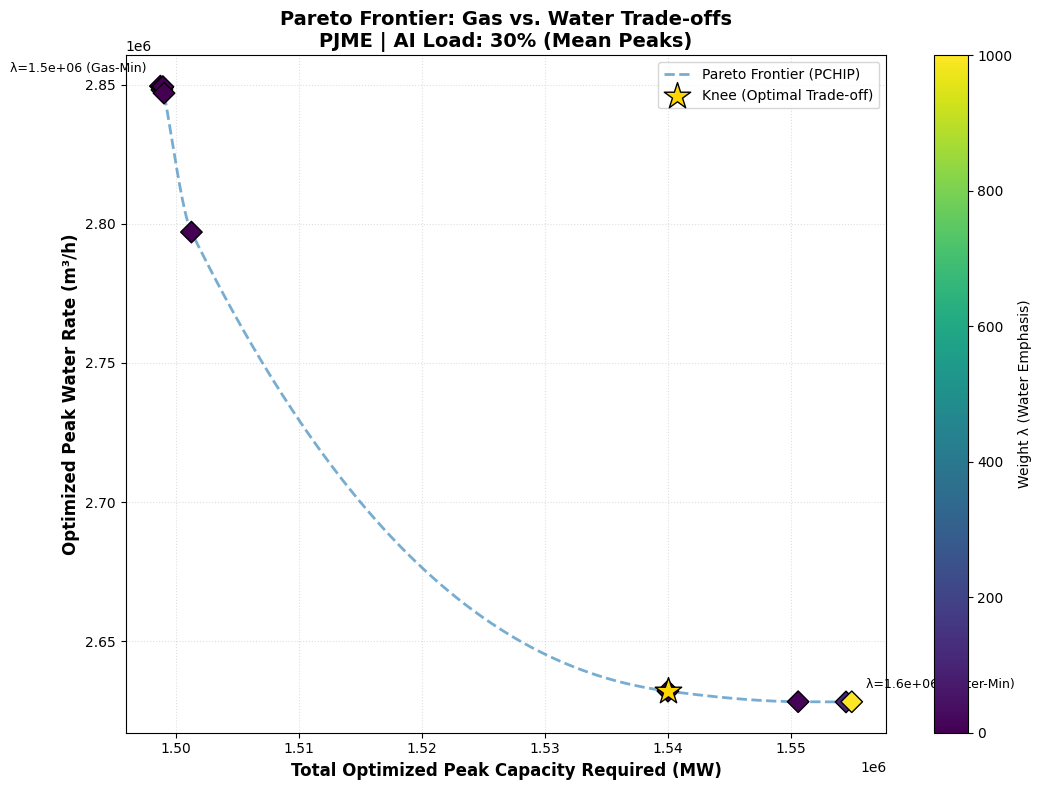

In [15]:
# @title 7. PARETO FRONTIER VISUALIZATION
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
import os

# 1. Load the optimized results
res_path = os.path.join(BASE_DIR, RESULTS_FILE)
if not os.path.exists(res_path):
    raise FileNotFoundError(f"Results file not found at {res_path}. Please run Cell 6 first.")

df = pd.read_csv(res_path)

# 2. Filter for the specific scenario to plot
target_region = df['region'].unique()[0]
target_ai = df['ai_fraction'].max()  # Usually 0.30/30% AI load
plot_df = df[(df['region'] == target_region) & (df['ai_fraction'] == target_ai)].copy()

# 3. Aggregate Trial Data (Mean across N=50)
summary = plot_df.groupby('water_weight').agg({
    'total_peak_mw': 'mean',
    'water_peak_m3h': 'mean'
}).reset_index().sort_values('total_peak_mw')

# Clean duplicates to ensure strictly increasing X for PCHIP
summary = summary.drop_duplicates(subset=['total_peak_mw'], keep='last')
x = summary['total_peak_mw'].values
y = summary['water_peak_m3h'].values

# 4. Visualization Logic
plt.figure(figsize=(11, 8), dpi=100)
ax = plt.gca()

if len(x) >= 3:
    # Generate smooth PCHIP curve
    x_smooth = np.linspace(x.min(), x.max(), 500)
    pchip = PchipInterpolator(x, y)
    y_smooth = pchip(x_smooth)
    plt.plot(x_smooth, y_smooth, 'tab:blue', linestyle='--', linewidth=2, alpha=0.6, label='Pareto Frontier (PCHIP)')

    # Automated "Knee" Detection (Normalizing to find max curvature)
    x_norm = (x - x.min()) / (x.max() - x.min())
    y_norm = (y - y.min()) / (y.max() - y.min())
    knee_idx = np.argmin(np.sqrt(x_norm**2 + y_norm**2))
    plt.scatter(x[knee_idx], y[knee_idx], color='gold', marker='*', s=400, edgecolors='black', zorder=10, label='Knee (Optimal Trade-off)')
else:
    plt.plot(x, y, 'tab:blue', linestyle='--', alpha=0.6)

# Scatter plot of individual weights
sc = plt.scatter(x, y, c=summary['water_weight'], cmap='viridis', s=120, marker='D', edgecolors='k', zorder=5)

# 5. Formatting
plt.title(f"Pareto Frontier: Gas vs. Water Trade-offs\n{target_region} | AI Load: {int(target_ai*100)}% (Mean Peaks)", fontsize=14, fontweight='bold')
plt.xlabel("Total Optimized Peak Capacity Required (MW)", fontsize=12, fontweight='bold')
plt.ylabel("Optimized Peak Water Rate (m³/h)", fontsize=12, fontweight='bold')
plt.colorbar(sc, label='Weight λ (Water Emphasis)')
plt.grid(True, which='both', linestyle=':', alpha=0.4)
plt.legend()

# Endpoint Annotations
plt.annotate(f'λ={x[0]:.1e} (Gas-Min)', (x[0], y[0]), textcoords="offset points", xytext=(-10,10), ha='right', fontsize=9)
plt.annotate(f'λ={x[-1]:.1e} (Water-Min)', (x[-1], y[-1]), textcoords="offset points", xytext=(10,10), ha='left', fontsize=9)

plt.tight_layout()
plt.show()